## Exercícios - Lab 25

Exercícios sobre funções, passagem de parâmetros e escopo.

### Exercício 0: Mutabilidade

Considere as funções $f$, $g$ e $h$ abaixo.

In [1]:
def f(L, x):
    L.append(x)
    L.append(x)

def g(L, x):
    L = L + [x, x]

def h(L, x):
    L = L + [x, x]
    return L

Preveja a saída de cada célula **antes de executar**! JUSTIFIQUE (mentalmente). Convença-se do porquê de cada comportamento.

In [ ]:
A = [1, 2]
f(A, 3)
print(A) # QUAL A SAÍDA?

[1, 2, 3, 3]


In [ ]:
AZ = [1, 2]
AZ = f(AZ, 3)
print(AZ) # QUAL A SAÍDA?

None


In [4]:
B = [1, 2]
g(B, 3)
print(B) # QUAL A SAÍDA?

[1, 2]


In [5]:
BZ = [1, 2]
BZ = g(BZ, 3)
print(BZ) # QUAL A SAÍDA?

None


In [6]:
C = [1, 2]
h(C, 3)
print(C) # QUAL A SAÍDA?

[1, 2]


In [7]:
CZ = [1, 2]
CZ = h(CZ, 3)
print(CZ) # QUAL A SAÍDA?

[1, 2, 3, 3]


### Exercício 1: Parâmetro padrão

Implemente uma função chamada `calcular_variancia` que recebe uma lista de números e um parâmetro opcional `amostral` com valor padrão `True`.

- Se `amostral` for `True`, a lista de entrada é interpretada como amostra (divisão por $n - 1$).
- Se `amostral` for `False`, a lista de entrada é interpretada como população (divisão por $n$).

Em seguida, implemente a função `calcular_desvio_padrao` que recebe a mesma lista e o parâmetro `amostral`. Ela deve reaproveitar a função `calcular_variancia` chamando-a internamente e retornar a raiz quadrada do resultado.

In [8]:
dados = [10, 12, 23, 23, 16, 23, 21, 16]

avg = sum(dados) / len(dados)

# DEFINA AS FUNÇÕES AQUI
def calcular_variancia(data, amostral=True):
    q = (len(data) - 1) if amostral else (len(data))
    summ = 0
    for r in data:
        summ += (avg - r)**2
    return summ / q

def calcular_desvio_padrao(data, amostral=True):
    return (calcular_variancia(data, amostral))**0.5

var_amostral = calcular_variancia(dados)
var_populacional = calcular_variancia(dados, amostral=False)

dp_amostral = calcular_desvio_padrao(dados)
dp_populacional = calcular_desvio_padrao(dados, amostral=False)

print(f"Variancia amostral: {var_amostral:.4f}")
print(f"Variancia populacional: {var_populacional:.4f}")
print(f"Desvio padrao amostral: {dp_amostral:.4f}")
print(f"Desvio padrao populacional: {dp_populacional:.4f}")

Variancia amostral: 27.4286
Variancia populacional: 24.0000
Desvio padrao amostral: 5.2372
Desvio padrao populacional: 4.8990


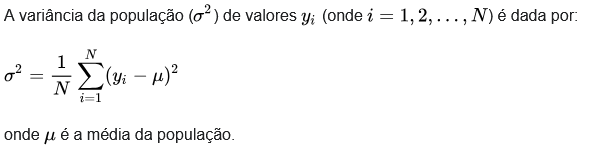

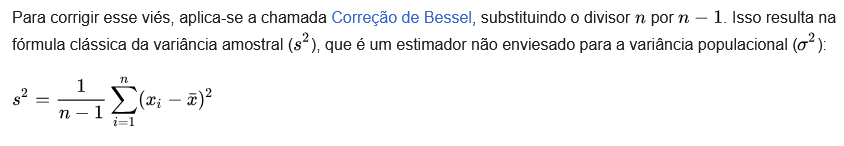

em que $\overline x$ é a média amostral.

**Saída esperada**
```
Variancia amostral: 27.4286
Variancia populacional: 24.0000
Desvio padrao amostral: 5.2372
Desvio padrao populacional: 4.8990
```

### Exercício 2: Padronização por z-score

O cálculo do z-score de uma observação é dado por

$$z = \dfrac{x - \mu}{\sigma}$$

em que $\mu$ é a média e $\sigma$ o desvio padrão das observações. (Considere o desvio padrão amostral)

Crie uma função chamada `padronizar_amostra(amostra)` em que `amostra` é uma lista de observações.
- Dentro da função, guarde em variáveis locais `media` e `desvio_padrao` os resultados intermediários. Calcule e retorne uma nova lista contendo os z-scores de cada elemento.
- Responda antes de executar: a variável `media` definida no teste abaixo (global) será alterada?

**Saída esperada**
```
Escores z: [-1.4, -0.47, -0.47, -0.47, 0.0, 0.0, 0.94, 1.87]
Valor da variavel media fora da funcao: 0.0
```

In [10]:
media = 0.0 # teste

# DEFINA padronizar_amostra AQUI
def desvio_padrao(amostra, media):
    summ = 0
    for r in amostra:
        summ += (media - r)**2
    return (summ / (len(amostra)-1))**0.5

def zscore(r, avg, dp):
    return (r - avg)/dp

def padronizar_amostra(amostra):
    escores = []
    media = sum(amostra)/len(amostra)
    dp = desvio_padrao(amostra, media)
    for r in amostra:
        escores.append(zscore(r,media,dp))
    return escores

dados = [2, 4, 4, 4, 5, 5, 7, 9]

escores = padronizar_amostra(dados)

print("Escores z:", [round(z, 2) for z in escores]) # essa sintaxe de construção de lista aprenderemos em aulas futuras
print("Valor da variavel media fora da funcao:", media)

Escores z: [-1.4, -0.47, -0.47, -0.47, 0.0, 0.0, 0.94, 1.87]
Valor da variavel media fora da funcao: 0.0


### Exercício 3: Agrupamento

Crie uma função chamada `resumir_grupos(**grupos)` que recebe um número variável de amostras nomeadas via kwargs.
A função deve retornar um dicionário onde cada chave é o nome do grupo e o valor é um dicionário interno contendo:
- n: quantidade de observações.
- media: média aritmética do grupo.
- desvio: desvio padrão amostral (caso `n` seja menor que 2, defina o desvio como `0.0`).

**Saída esperada**
```
controle {'n': 4, 'media': 10.65, 'desvio': 0.38729833462074187}
tratamento_a {'n': 3, 'media': 12.766666666666666, 'desvio': 0.2516611478423584}
tratamento_b {'n': 5, 'media': 15.02, 'desvio': 0.1923538406167134}
```

In [11]:
# DEFINA resumir_grupos AQUI
def desvio_padrao(amostra):
    if len(amostra) < 2:
        return 0.0
    media = sum(amostra)/len(amostra)
    summ = 0
    for r in amostra:
        summ += (media - r)**2
    return (summ / (len(amostra)-1))**0.5

def resumir_grupos(**grupos):
    resumo = {}
    for k,v in grupos.items():
        d = {
            'n': len(v),
            'media': sum(v)/len(v),
            'desvio': desvio_padrao(v)
        }
        resumo[k] = d
    return resumo

resumo = resumir_grupos(
    controle=[10.2, 11.1, 10.8, 10.5],
    tratamento_a=[12.5, 13.0, 12.8],
    tratamento_b=[15.1, 14.9, 15.3, 15.0, 14.8]
)

for grupo, metricas in resumo.items():
    print(grupo, metricas)

controle {'n': 4, 'media': 10.649999999999999, 'desvio': 0.38729833462074187}
tratamento_a {'n': 3, 'media': 12.766666666666666, 'desvio': 0.2516611478423584}
tratamento_b {'n': 5, 'media': 15.02, 'desvio': 0.1923538406167134}


### Exercício 4: Variância combinada

Quando temos $k$ amostras independentes provenientes de populações com mesma variância, calculamos a variância combinada (*pooled variance*), dada por

$$s_p^2 = \frac{\sum_{i=1}^{k} (n_i - 1) s_i^2}{\sum_{i=1}^{k} (n_i - 1)}$$

em que $n_i$ é o tamanho da $i$-ésima amostra e $s_i^2$ é a sua variância amostral.

Implemente a função `calcular_variancia_combinada(*amostras)` que receba uma quantidade variável de amostras (listas de números) via `*args`.
A função deve reaproveitar a função `calcular_variancia` do Exercício 1 para obter cada $s_i^2$ e retornar o valor final de $s_p^2$.

**Saída esperada**
```
Variancia combinada: 3.1083
```

In [2]:
# DEFINA calcular_variancia_combinada AQUI
def calcular_variancia(data, amostral=True):
    avg = sum(data) / len(data)
    q = (len(data) - 1) if amostral else (len(data))
    summ = 0
    for r in data:
        summ += (avg - r)**2
    return summ / q

def calcular_variancia_combinada(*amostras):
    p = 0
    q = 0
    for amostra in amostras:
        p += (len(amostra)-1) * calcular_variancia(amostra)
        q += len(amostra)-1
    return p / q

amostra_1 = [12, 15, 14, 10, 13]
amostra_2 = [18, 17, 19, 16]
amostra_3 = [22, 25, 24, 21, 23, 20]

var_combinada = calcular_variancia_combinada(amostra_1, amostra_2, amostra_3)

print(f"Variancia combinada: {var_combinada:.4f}")

Variancia combinada: 3.1083


### Exercício 5: Covariância e correlação de Pearson

A covariância amostral entre duas variáveis $X$ e $Y$ de mesmo tamanho $n$ mede o grau de associação linear entre elas:

$$\text{Cov}(X, Y) = \frac{1}{n - 1} \sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})$$

em que $\overline x$ e $\overline y$ são as médias amostrais de $X$ e $Y$ respectivamente.

Com a covariância e os desvios padrões amostrais $s_x$ e $s_y$, calculamos o coeficiente de correlação linear de Pearson:

$$r = \frac{\text{Cov}(X, Y)}{s_x \cdot s_y}$$

Implemente a modularização desse cálculo:
1. Crie a função `calcular_covariancia(x, y)` que retorna a covariância amostral entre as duas listas.
2. Crie a função `calcular_correlacao(x, y)` que reaproveita `calcular_covariancia` e a função `calcular_desvio_padrao` do Exercício 1 para calcular e retornar $r$.

**Saída esperada**
```
Covariancia: 34.2500
Correlacao de Pearson: 0.9959
```

In [3]:
def calcular_variancia(data, amostral=True):
    avg = sum(data) / len(data)
    q = (len(data) - 1) if amostral else (len(data))
    summ = 0
    for r in data:
        summ += (avg - r)**2
    return summ / q

def calcular_desvio_padrao(data, amostral=True):
    return (calcular_variancia(data, amostral))**0.5

# DEFINA AS FUNÇÕES AQUI
def calcular_covariancia(x,y):
    n = len(x)
    avgx = sum(x) / n
    avgy = sum(y) / n
    summ = 0
    for i in range(n):
        summ += (x[i]-avgx)*(y[i]-avgy)
    return summ / (n-1)

def calcular_correlacao(x,y):
    return calcular_covariancia(x,y) / (calcular_desvio_padrao(x) * calcular_desvio_padrao(y))

horas_estudo = [2.0, 4.0, 5.0, 7.0, 8.0]
nota_exame = [55.0, 65.0, 70.0, 85.0, 90.0]

cov = calcular_covariancia(horas_estudo, nota_exame)
r = calcular_correlacao(horas_estudo, nota_exame)

print(f"Covariancia: {cov:.4f}")
print(f"Correlacao de Pearson: {r:.4f}")

Covariancia: 34.2500
Correlacao de Pearson: 0.9959


### Exercício 6: Atualização sequencial da média

Em fluxos contínuos de dados (*streaming*), a média pode ser atualizada a cada nova observação sem a necessidade de reprocessar todo o histórico, utilizando a relação recursiva

$$\bar{x}_n = \bar{x}_{n-1} + \frac{x_n - \bar{x}_{n-1}}{n}$$

Um analista tentou resolver o problema utilizando variáveis globais:

```python
media_global = 0.0
total_obs = 0

def acumular_dado(novo_valor):
    global media_global, total_obs
    total_obs += 1
    media_global += (novo_valor - media_global) / total_obs
```

Refatore esse processo eliminando o uso de `global`:
- Crie uma função chamada `atualizar_media(media_anterior, novo_dado, n)` que não usa `global`.


**Saída esperada**
```
Observação 1: dado = 10.0 | média acumulada = 10.0
Observação 2: dado = 12.0 | média acumulada = 11.0
Observação 3: dado = 14.0 | média acumulada = 12.0
Observação 4: dado = 16.0 | média acumulada = 13.0
Observação 5: dado = 18.0 | média acumulada = 14.0
```

In [14]:
# DEFINA atualizar_media AQUI
def atualizar_media(media_anterior, novo_dado, n):
    return media_anterior + (novo_dado - media_anterior)/n

fluxo_dados = [10.0, 12.0, 14.0, 16.0, 18.0]
media_atual = 0.0

# AQUI, ITERE SOBRE O FLUXO DE DADOS E ATUALIZE A MÉDIA DE MODO INCREMENTAL (atualizar_media), UMA OBSERVAÇÃO POR VEZ
i = 1
for r in fluxo_dados:
    media_atual = atualizar_media(media_atual, r, i)
    print(f'Observação {i}: dado = {r} | média acumulada = {media_atual}') 
    i+=1

Observação 1: dado = 10.0 | média acumulada = 10.0
Observação 2: dado = 12.0 | média acumulada = 11.0
Observação 3: dado = 14.0 | média acumulada = 12.0
Observação 4: dado = 16.0 | média acumulada = 13.0
Observação 5: dado = 18.0 | média acumulada = 14.0
